In [78]:
import json
import os
import wordfreq
from collections import Counter
from wordfreq import top_n_list

current_file_path = os.getcwd()
json_path = os.path.join(current_file_path, 'long-eng.json')
low_eng_path = os.path.join(current_file_path, 'low-eng.json')
non_wiki_path = os.path.join(current_file_path, 'non-wiki-eng.json')
spanish_path = os.path.join(current_file_path, 'spanish.json')
polish_path = os.path.join(current_file_path, 'polish.json')

/home/jarek/PycharmProjects/Zaliczenie/analysis/polish.json


In [ ]:
# Wczytam teraz statystyki z pobranych artykułów
# Każdy z nich zostanie posortowany

In [86]:
with open(json_path, 'r') as file:
    long_article_dict = json.load(file)
    long_article_dict = dict(sorted(long_article_dict.items(), key=lambda item: -item[1]))
with open(low_eng_path, 'r') as file:
    low_f_dict = json.load(file)
    low_f_dict = dict(sorted(low_f_dict.items(), key=lambda item: -item[1]))
with open(spanish_path, 'r') as file:
    spanish_dict = json.load(file)
    spanish_dict = dict(sorted(spanish_dict.items(), key=lambda item: -item[1]))
with open(non_wiki_path, 'r') as file:
    english_non_wiki = json.load(file)
    english_non_wiki = dict(sorted(english_non_wiki.items(), key=lambda item: -item[1]))
with open(polish_path, 'r') as file:
    polish_dict = json.load(file)
    polish_dict = dict(sorted(polish_dict.items(), key=lambda item: -item[1]))

k = 1000
top_k_list_eng = top_n_list('en', k)
top_k_list_esp = top_n_list('es', k)
top_k_list_pol = top_n_list('pl', k)

In [ ]:
# Teraz zdefiniuję funkcję. Sprawdza ona ile z k najczęściej używanych słów w danym artykule, znajduje się w k najczęściej używanych słów w danym języku

In [80]:
def f(slowa_w_tekscie, slowa_w_jezyku, k):
    k_dostosowane = min(k, min(len(slowa_w_tekscie), len(slowa_w_jezyku)))
    slowa_w_jezyku = list(slowa_w_jezyku)
    slowa_w_tekscie = list(slowa_w_tekscie)
    slowa_w_jezyku = slowa_w_jezyku[:k_dostosowane]
    slowa_w_tekscie = slowa_w_tekscie[:k_dostosowane]
    ret = sum([1 if slowo_z_tekstu in slowa_w_jezyku else 0
               for slowo_z_tekstu in slowa_w_tekscie]) / k_dostosowane * 100
    return ret

In [ ]:
# Obliczę wartość funkcji dla każdego z trzech języków, dla każdego z 5 tekstów

In [87]:
k_range = [3, 10, 100, 1000]
languages = [top_k_list_eng, top_k_list_esp, top_k_list_pol]
wyniki = []
for i in range (0, len(languages)):
    lang = languages[i]
    wyniki.append([])
    for j in range (0, len(k_range)):
        k_case = k_range[j]
        f_1_long_art = f(long_article_dict, lang, k_case)
        f_2_eng_low = f(low_f_dict, lang, k_case)
        f_3_non_wiki = f(english_non_wiki, lang, k_case)
        f_4_spanish = f(spanish_dict, lang, k_case)
        f_5_polish = f(polish_dict, lang, k_case)
        y = [f_1_long_art, f_2_eng_low, f_3_non_wiki, f_4_spanish, f_5_polish]
        wyniki[i].append(y)
wyniki_eng = wyniki[0]
wyniki_esp = wyniki[1]
wyniki_pol = wyniki[2]

In [88]:
# Umieszczę dane na wykresach

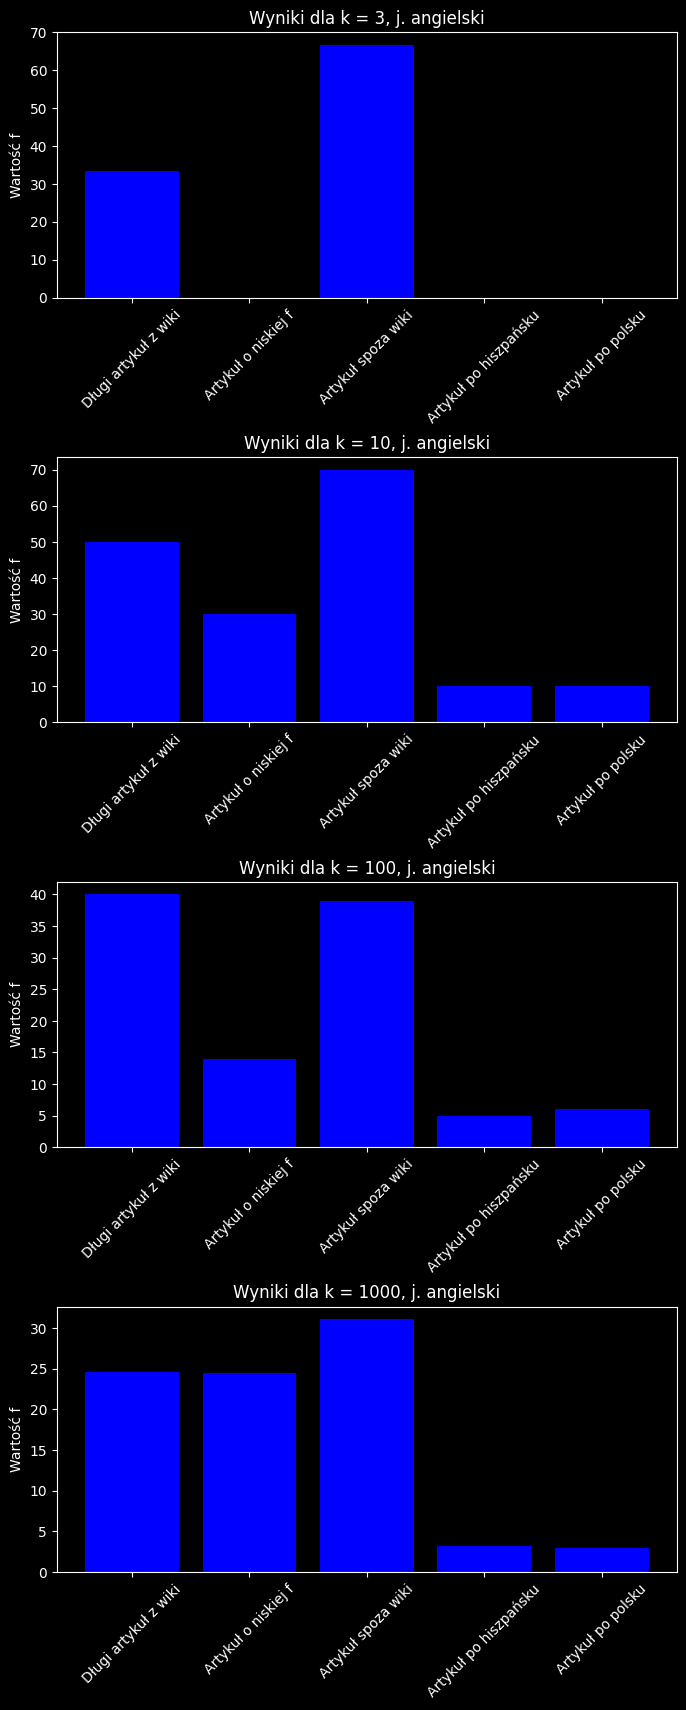

In [93]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(len(wyniki_eng), 1, figsize=(8, 20))
x_podpisy = ['Długi artykuł z wiki', 'Artykuł o niskiej f', 'Artykuł spoza wiki', 'Artykuł po hiszpańsku', 'Artykuł po polsku']

for i in range(0, len(wyniki[0])):
    axs[i].bar(x_podpisy, wyniki_eng[i], color='blue')
    axs[i].set_title(f"Wyniki dla k = {k_range[i]}, j. angielski")
    axs[i].set_ylabel("Wartość f")
    axs[i].tick_params(axis='x', rotation=45)

plt.subplots_adjust(hspace=0.6)
plt.show()

In [ ]:
# Zwizualizuję teraz wyniki - w nieco inny sposób - dla funkcji mierzącej zgodność z j. polskim i j. hiszpańskim

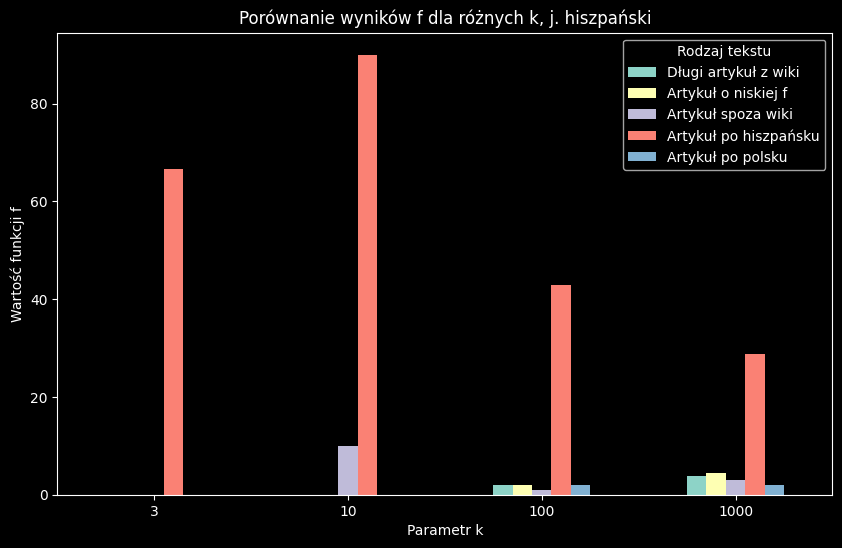

In [90]:
import pandas as pd
k_range = ['3', '10', '100', '1000']
x_podpisy = ['Długi artykuł z wiki (ang)', 'Artykuł o niskiej f (ang)', 'Artykuł spoza wiki (ang)', 'Artykuł po hiszpańsku', 'Artykuł po polsku']

df = pd.DataFrame(wyniki[1], index=k_range, columns=x_podpisy)

df.plot(kind='bar', figsize=(10, 6))

plt.title("Porównanie wyników f dla różnych k, j. hiszpański")
plt.ylabel("Wartość funkcji f")
plt.xlabel("Parametr k")
plt.legend(title="Rodzaj tekstu")
plt.xticks(rotation=0)
plt.show()

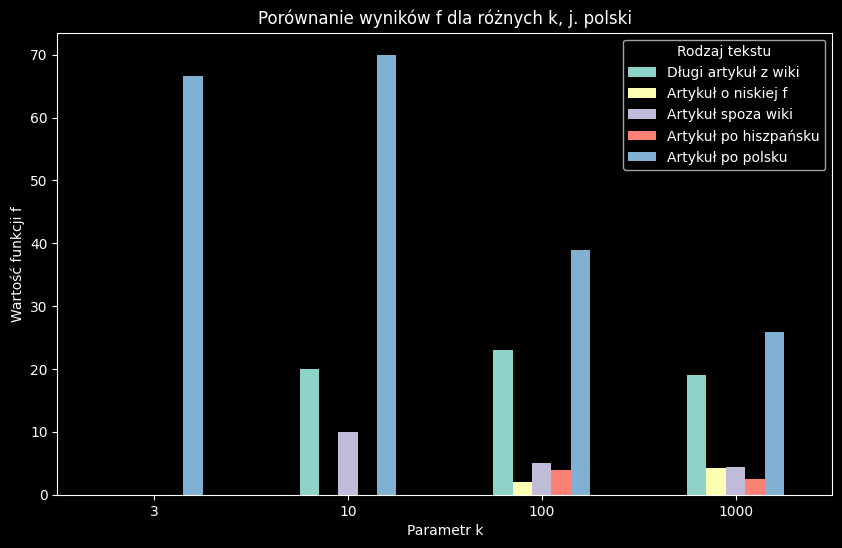

In [94]:
import pandas as pd

df = pd.DataFrame(wyniki[2], index=k_range, columns=x_podpisy)
df.plot(kind='bar', figsize=(10, 6))

plt.title("Porównanie wyników f dla różnych k, j. polski")
plt.ylabel("Wartość funkcji f")
plt.xlabel("Parametr k")
plt.legend(title="Rodzaj tekstu")
plt.xticks(rotation=0)
plt.show()

In [92]:
# OPIS WYNIKÓW
# Bardzo prosta funkcja, którą zastosowałem, wydaje się całkiem skuteczna w przewidywaniu języka, w którym został napisany tekst.
# Co istotne, funkcja rzeczywiście radzi sobie lepiej przy dużej ilości tekstu. Co prawda dopasowanie bezwzględne spada, jednak kontrast między pewnością dla różnych języków rośnie, co pozwala na jednoznaczne odróżnienie języka.
# Co ciekawe, funkcja wydaje się użyteczna nawet dla k równego 3.
# Dobór języków okazał się istotny — funkcja poradziła sobie znacznie gorzej z językiem polskim. Dla k = 1000 zaobserwowano dopasowanie na poziomie ok. 25, co jest tylko trochę wyższe od pewności dla tekstu w j. anielskim. Prawdopodobnie niska pewność co do j. polskiego wynika z wielu form i odmian najczęściej używanych słów.
# Znalezienie artykułu o niskim wyniku f było umiarkowanie trudne. Przyjąłem strategię, aby szukać tekstu jak najkrótszego (powyżej 20) słów, co maksymalizowało szanse na nierównomierny rozkład słów i dzięki temu niskie dopasowanie. Jednak dla k = 1000, funkcja wciąż zdołała poprawnie dopasować tekst. Wydaje mi się, że gdyby udało się znaleźć tekst o długości między 20 a 30 znaków, jego dopasowanie byłoby około jeszcze o połowę niższe.